# Import Library

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine


# Koneksikan ke Database

In [4]:
DB_USER = "postgres"
DB_PASS = "1234"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "olist.db"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

print("Koneksi ke database berhasil")

Koneksi ke database berhasil


In [4]:
df_test = pd.read_sql("SELECT * FROM orders LIMIT 5;", engine)
df_test

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


# Analisis Pertanyaan Bisnis 

## 1 Late Delivery Rate

In [ ]:
df_q1 = pd.read_sql("SELECT * FROM late_delivery_rate_vw", engine)
print("--- Hasil Analisis Late Delivery Rate ---")
display(df_q1)


--- Hasil Analisis Late Delivery Rate ---


,delivery_status,total_orders,percentage
0,late,15652,8.11
1,On-Time/Early,177288,91.89


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_18136\4128928837.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_q1, x="delivery_status", y="total_orders", palette=["#cd3ce7", "#4bcc2e"])


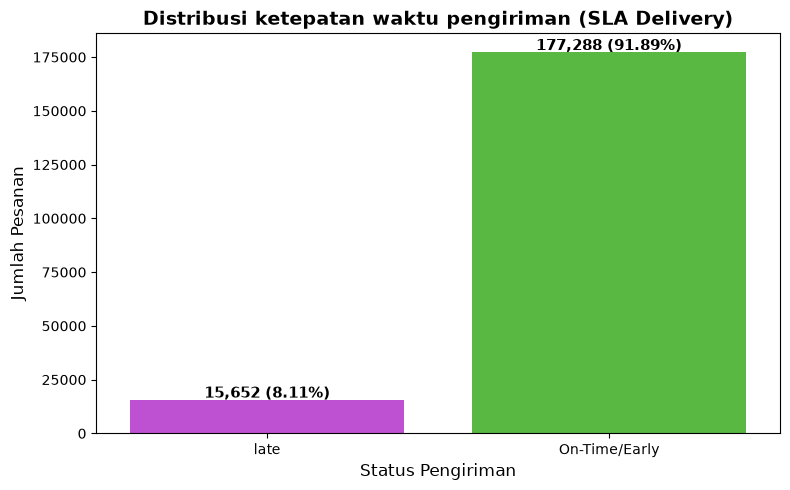

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_q1, x="delivery_status", y="total_orders", palette=["#cd3ce7", "#4bcc2e"])

plt.title("Distribusi ketepatan waktu pengiriman (SLA Delivery)", fontsize=14, fontweight='bold')
plt.xlabel("Status Pengiriman", fontsize=12)
plt.ylabel("Jumlah Pesanan", fontsize=12)

#menambahkan label angka diatas bar
for index, row in df_q1.iterrows():
    plt.text(index, row['total_orders'] + 1000, f"{row['total_orders']:,} ({row['percentage']}%)", 
             ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

Secara sekilas, angka 8,11% terlambat tampak relatif kecil (~91,89% on-time). Namun, dalam ekosistem e-commerce dan logistik skala besar, 8,11% dari puluhan ribu pesanan berarti ada ribuan pembeli yang kecewa, berpotensi mengajukan komplain, menuntut ganti rugi ongkir, atau bahkan tidak akan pernah berbelanja lagi di platform.

## 2 Keterlambatan per Seller

In [7]:

df_q2 = pd.read_sql("SELECT * FROM keterlambatan_per_seller", engine)
print("--- 10 Seller Teratas dengan Rata-rata Keterlambatan Terparah ---")
display(df_q2)

--- 10 Seller Teratas dengan Rata-rata Keterlambatan Terparah ---


,seller_id,total_late_orders,avg_delay_days
0,ad420dd0c4f92f8af951ac24b86d0cf5,12,64.7
1,e81e1f9c3e762e620f3fb60a51499e16,8,63.0
2,eebb3372362aa9a46975164bed19a7e7,8,62.0
3,ebd2d60905fb58271facef5596b620d3,12,55.0
4,8cc6a0e5738e61a87b03c78b2ba9db4b,8,53.0
5,cb41bfbcbda0aea354a834ab222f9a59,16,49.8
6,93dc87703c046b603023e75222018b45,12,47.3
7,82e0a475a88cc9595229d8029273f045,20,47.2
8,c847e075301870dd144a116762eaff9a,16,46.0
9,066a6914e1ebf3ea95a216c73a986b91,12,43.3


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_18136\1251025770.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_q2, x='avg_delay_days', y='seller_id', palette='Reds_r')


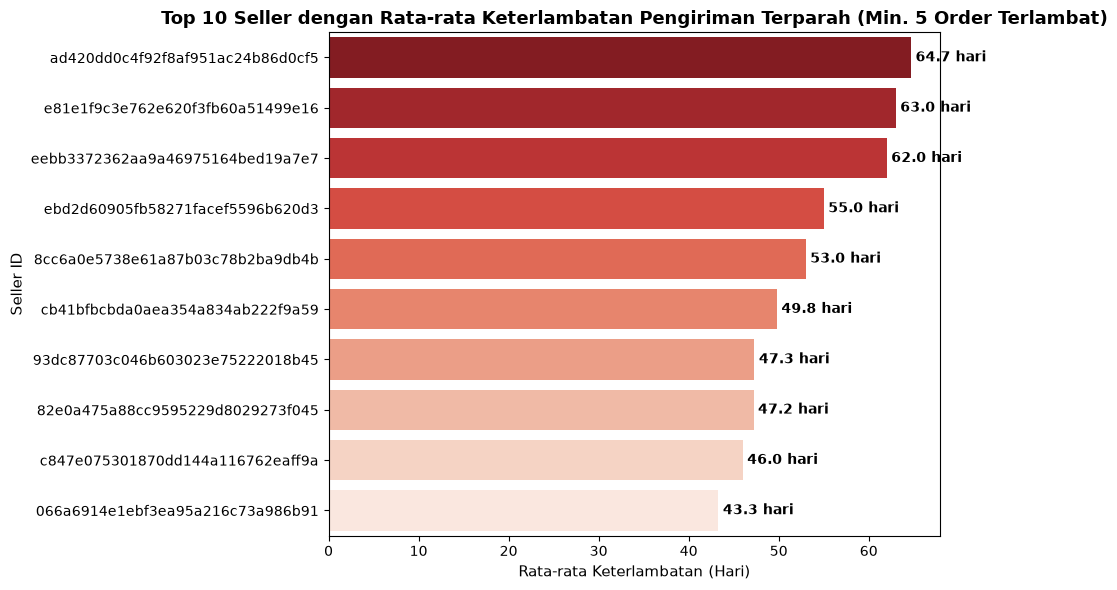

In [8]:
# 3. Visualisasi Bar Chart Horizontal
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_q2, x='avg_delay_days', y='seller_id', palette='Reds_r')

plt.title('Top 10 Seller dengan Rata-rata Keterlambatan Pengiriman Terparah (Min. 5 Order Terlambat)', fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata Keterlambatan (Hari)', fontsize=11)
plt.ylabel('Seller ID', fontsize=11)

# Menambahkan label angka di samping bar
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width} hari',
                (width + 0.5, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 3 Analisis Wilayah / Geografi

In [17]:
df_q3 = pd.read_sql("SELECT * FROM analisis_geografi", engine)
print("--- Top 5 Wilayah (State) dengan Persentase Keterlambatan Tertinggi ---")
display(df_q3)

--- Top 5 Wilayah (State) dengan Persentase Keterlambatan Tertinggi ---


,customer_state,total_orders,total_late_orders,late_rate_percentage
0,AL,2382,570,23.93
1,MA,4302,846,19.67
2,PI,2856,456,15.97
3,CE,7674,1176,15.32
4,SE,2010,306,15.22


In [18]:
query_q3_rata_rata ="""
SELECT 
    COUNT(o.order_id) AS total_orders_all,
    COUNT(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 END) AS total_late_orders_all,
    ROUND(
        COUNT(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 END) * 100.0 / COUNT(o.order_id), 
        2
    ) AS overall_late_rate_percentage
FROM orders o
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL;
""" 

df_query_q3_ratarata = pd.read_sql(query_q3_rata_rata, engine)
print("persentase rata rate keterlambatan")
display(df_query_q3_ratarata)

persentase rata rate keterlambatan


,total_orders_all,total_late_orders_all,overall_late_rate_percentage
0,192940,15652,8.11


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_18136\779086053.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_q3, x='customer_state', y='late_rate_percentage', palette='Oranges_r')


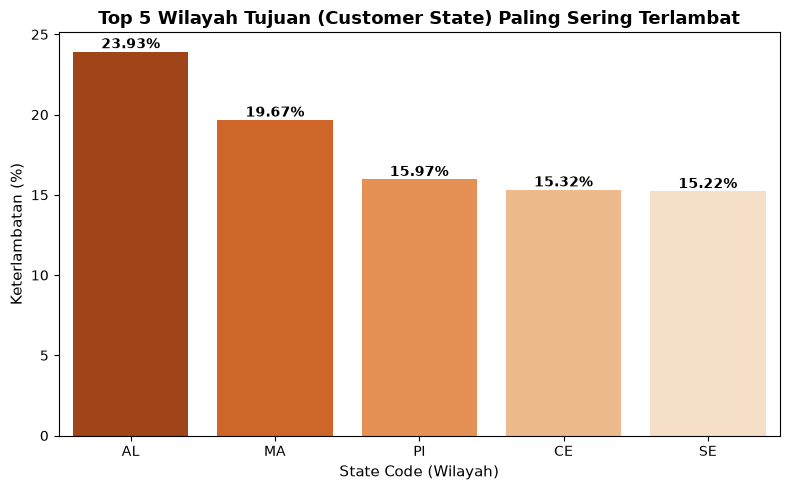

In [19]:
# 3. Visualisasi Bar Plot Vertikal dengan Highlight Warna
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_q3, x='customer_state', y='late_rate_percentage', palette='Oranges_r')

plt.title('Top 5 Wilayah Tujuan (Customer State) Paling Sering Terlambat', fontsize=13, fontweight='bold')
plt.xlabel('State Code (Wilayah)', fontsize=11)
plt.ylabel('Keterlambatan (%)', fontsize=11)

# Menambahkan label persentase di atas batang
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}%',
                (p.get_x() + p.get_width() / 2., height ),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Dibandingkan dengan baseline nasional rata-rata keterlambatan yang hanya 8,11%, wilayah Alagoas memiliki tingkat keterlambatan hampir 3 kali lipat lebih parah. Ini menunjukkan adanya masalah sistemik pada jalur logistik ke area tersebut 

## 4 Dampak Biaya Ongkir / Freight Value

In [20]:

df_q4 = pd.read_sql("SELECT * FROM dampak_biaya_ongkir", engine)
print("Perbandingan biyaya ongkir on-time vs late")
display(df_q4)

Perbandingan biyaya ongkir on-time vs late


,delivery_status,avg_freight_value,avg_price
0,Late,22.11,133.00
1,On-time,19.76,118.86


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_18136\3565400408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_q4, x='delivery_status', y='avg_freight_value', palette=['#2ecc71', '#e74c3c'])


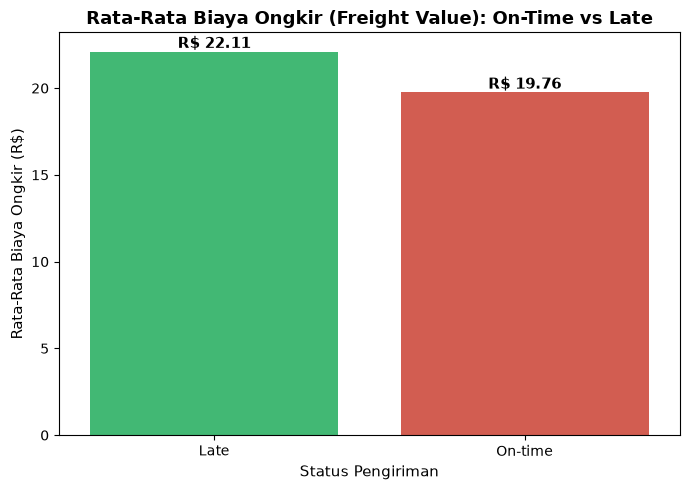

In [21]:
# 3. Visualisasi Bar Plot Perbandingan Ongkir
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=df_q4, x='delivery_status', y='avg_freight_value', palette=['#2ecc71', '#e74c3c'])

plt.title('Rata-Rata Biaya Ongkir (Freight Value): On-Time vs Late', fontsize=13, fontweight='bold')
plt.xlabel('Status Pengiriman', fontsize=11)
plt.ylabel('Rata-Rata Biaya Ongkir (R$)', fontsize=11)

# Menambahkan label angka di atas batang
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'R$ {height:.2f}',
                (p.get_x() + p.get_width() / 2., height ),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 5 Dampak Keterlambatan ke Rating / Review Score

In [22]:
df_q5 = pd.read_sql("SELECT * FROM dampak_keterlambaptan_ke_rating", engine)
display(df_q5)

,delivery_status,total_orders,avg_reviw_score,persentase_rating_bintang_1
0,Late,7661,2.57,46.0
1,On-time,88163,4.29,6.0


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_19572\4007734468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_q5, x='delivery_status', y='avg_reviw_score', palette=['#2ecc71', '#e74c3c'])
c:\miniconda3\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


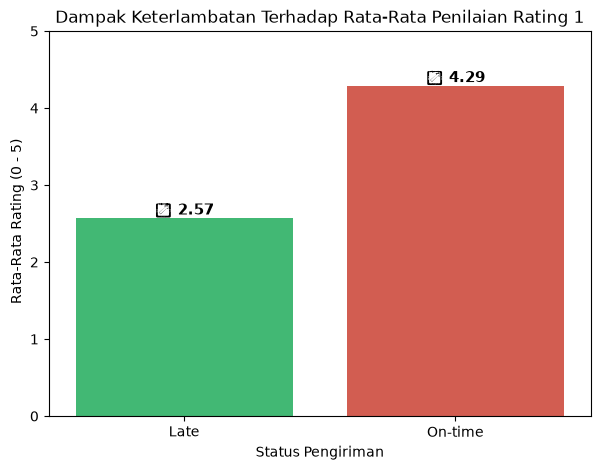

In [44]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=df_q5, x='delivery_status', y='avg_reviw_score', palette=['#2ecc71', '#e74c3c'])

plt.title("Dampak Keterlambatan Terhadap Rata-Rata Penilaian Rating 1")
plt.xlabel("Status Pengiriman")
plt.ylabel(" Rata-Rata Rating (0 - 5)")
plt.ylim(0,5)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'⭐ {height:.2f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

Drop rating dari 4,29 (On-Time) ke 2,57 (Late) adalah penurunan yang sangat drastis (anjlok hampir 40%). Angka ini membuktikan secara kuantitatif bahwa keterlambatan pengiriman adalah penyebab utama hancurnya kepuasan pelanggan di platform ini.

## 6 Kategori Produk Paling Sering Terlambat

In [23]:

df_q6 = pd.read_sql("SELECT * FROM kategori_produk_paling_sering_terlambat", engine)
display(df_q6)

,product_category,total_orders,total_late_orders,late_rate_percentage
0,fashion_underwear_e_moda_praia,117,15,12.0
1,audio,348,45,12.0
2,casa_conforto,392,41,10.0
3,livros_tecnicos,256,28,10.0
4,artigos_de_natal,125,12,9.0


C:\Users\qruzeeta prasna\AppData\Local\Temp\ipykernel_19572\3325428583.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_q6, x='late_rate_percentage', y='product_category', palette='magma')


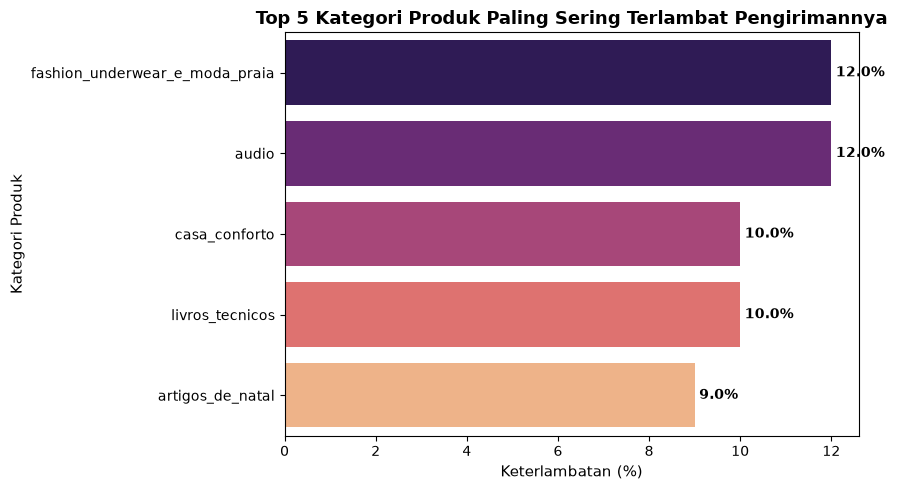

In [48]:
# 3. Visualisasi Bar Plot Horizontal untuk Kategori Produk
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_q6, x='late_rate_percentage', y='product_category', palette='magma')

plt.title('Top 5 Kategori Produk Paling Sering Terlambat Pengirimannya', fontsize=13, fontweight='bold')
plt.xlabel('Keterlambatan (%)', fontsize=11)
plt.ylabel('Kategori Produk', fontsize=11)

# Menambahkan label angka di samping bar
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width}%',
                (width + 0.1, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()